# VALORA AI: Better Data, Better Predictions
## Notebook 03: model comparison with repeated grouped nested cross-validation

**What is compared:**
- **5 baselines:** B0-B4, from a constant up to neighbourhood and year-adjusted €/m².
- **18 candidates:** 6 models (Linear Regression, Ridge, Lasso, Elastic Net, Random Forest, Extra Trees) × 3 feature sets (A, B, C).
- **The nested selection procedure (NS),** which picks one of the 18 candidates inside each training fold.

**How (locked in `docs/EVALUATION_PROTOCOL.md`):**
- **Outer CV:** 10 repeats × grouped 5-fold CV on the 73 valuation clusters, giving 50 outer folds.
- **Inner CV:** grouped 5-fold CV inside each outer training part, for tuning.
- **Same folds for every method.**

The run takes about 10-15 minutes. Its results are saved to `results/cv_*.csv`, and notebook 04 evaluates them.

**What this code does:** Sets up the paths and loads the modelling table.

**Why we need it:** Every notebook starts from the same saved table.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'budva_data.py').exists():      # works when started from notebooks/ or from the project root
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Start Jupyter inside the VALORA_BUDVA_APPRAISAL_EXPERIMENT folder')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 90)

import json
import budva_data as bd
import budva_eval as be
import budva_plots as bp
from budva_models import BASELINES, candidate_ids
m = bd.load_model_table()
lock = json.loads((bd.RESULTS_DIR / 'protocol_lock.json').read_text(encoding='utf-8'))
assert bd.sha256(ROOT / lock['protocol_file']) == lock['sha256'], 'the evaluation protocol was changed after it was locked'
print('protocol unchanged since', lock['locked_at'], '| properties:', len(m), '| clusters:', m['valuation_cluster'].nunique())

protocol unchanged since 2026-11-25T15:17:41+01:00 | properties: 80 | clusters: 73


**What this code does:** Runs the repeated grouped nested cross-validation for all baselines, all 18 candidates and the nested selection procedure.

**Why we need it:** This is the core experiment: every method is scored on the same 50 outer folds, with all tuning done inside the training part.

In [2]:
preds, folds, coefs = be.run_nested_cv(m, n_jobs=2)
preds.drop(columns='row').to_csv(bd.RESULTS_DIR / 'cv_predictions.csv', index=False, encoding='utf-8', lineterminator='\n')
folds.to_csv(bd.RESULTS_DIR / 'cv_fold_scores.csv', index=False, encoding='utf-8', lineterminator='\n')
coefs.to_csv(bd.RESULTS_DIR / 'cv_coefficients.csv', index=False, encoding='utf-8', lineterminator='\n')
print('predictions:', len(preds), '| fold results:', len(folds), '| methods:', folds['model_id'].nunique())

predictions: 19200 | fold results: 1200 | methods: 24


## 1. Summary of all methods

**What this code does:** Computes MAE, RMSE, median absolute error, R² and training MAE for every method, and saves the summary.

**Why we need it:** One table shows all methods on the same folds; the min-max over repeats and the fold standard deviation show the stability.

In [3]:
summary = be.summary_table(preds, folds)
summary.to_csv(bd.RESULTS_DIR / 'cv_summary.csv', index=False, encoding='utf-8', lineterminator='\n')
strongest = be.strongest_baseline(summary)
show = summary[['model_id', 'kind', 'MAE', 'MAE_min', 'MAE_max', 'RMSE', 'MedAE', 'R2', 'fold_MAE_sd', 'train_MAE']].copy()
show['vs strongest baseline (%)'] = 100 * (summary.loc[summary['model_id'] == strongest, 'MAE'].iloc[0] - show['MAE']) / summary.loc[summary['model_id'] == strongest, 'MAE'].iloc[0]
print('strongest baseline:', strongest, '-', BASELINES[strongest][0])
show.sort_values('MAE').round({'MAE': 0, 'MAE_min': 0, 'MAE_max': 0, 'RMSE': 0, 'MedAE': 0, 'R2': 3, 'fold_MAE_sd': 0,
                               'train_MAE': 0, 'vs strongest baseline (%)': 1})

strongest baseline: B3 - B3 Year median €/m² × area


,model_id,kind,MAE,MAE_min,MAE_max,RMSE,MedAE,R2,fold_MAE_sd,train_MAE,vs strongest baseline (%)
16,Elastic Net | C,candidate,37946.0,34718.0,40380.0,61638.0,20123.0,0.714,11877.0,28632.0,15.7
13,Lasso | C,candidate,38923.0,36004.0,42829.0,62142.0,21561.0,0.710,11595.0,28913.0,13.6
15,Elastic Net | B,candidate,40001.0,36970.0,42503.0,63703.0,23396.0,0.695,12170.0,33329.0,11.2
12,Lasso | B,candidate,40002.0,37304.0,42133.0,63332.0,24276.0,0.699,12299.0,33776.0,11.2
9,Ridge | B,candidate,40049.0,37355.0,42267.0,65501.0,21608.0,0.678,12657.0,30360.0,11.1
10,Ridge | C,candidate,41131.0,36945.0,48120.0,66847.0,20457.0,0.663,13554.0,22767.0,8.7
17,Random Forest | A,candidate,42178.0,37200.0,47489.0,73102.0,21462.0,0.599,14784.0,28944.0,6.3
23,NS: nested selection,nested selection,42250.0,38647.0,45843.0,69250.0,22378.0,0.639,13557.0,28266.0,6.2
8,Ridge | A,candidate,42658.0,40614.0,46000.0,69659.0,21527.0,0.636,14382.0,30085.0,5.3
11,Lasso | A,candidate,42838.0,39280.0,45176.0,67939.0,23597.0,0.654,13513.0,34920.0,4.9


**How to read the table:**
- **`MAE`:** the mean over the 10 repeats of the MAE on all 80 out-of-fold predictions.
- **`MAE_min` / `MAE_max`:** the range over the repeats.
- **`train_MAE`:** the error on the training part. A large gap between it and `MAE` signals over-fitting.
- **Positive "vs strongest baseline":** the method has a lower MAE than the strongest baseline. This descriptive number is not yet the decision; the paired test with its uncertainty is in notebook 04.

**What this code does:** Draws all methods in one chart.

**Why we need it:** It gives the full picture before the formal comparison.

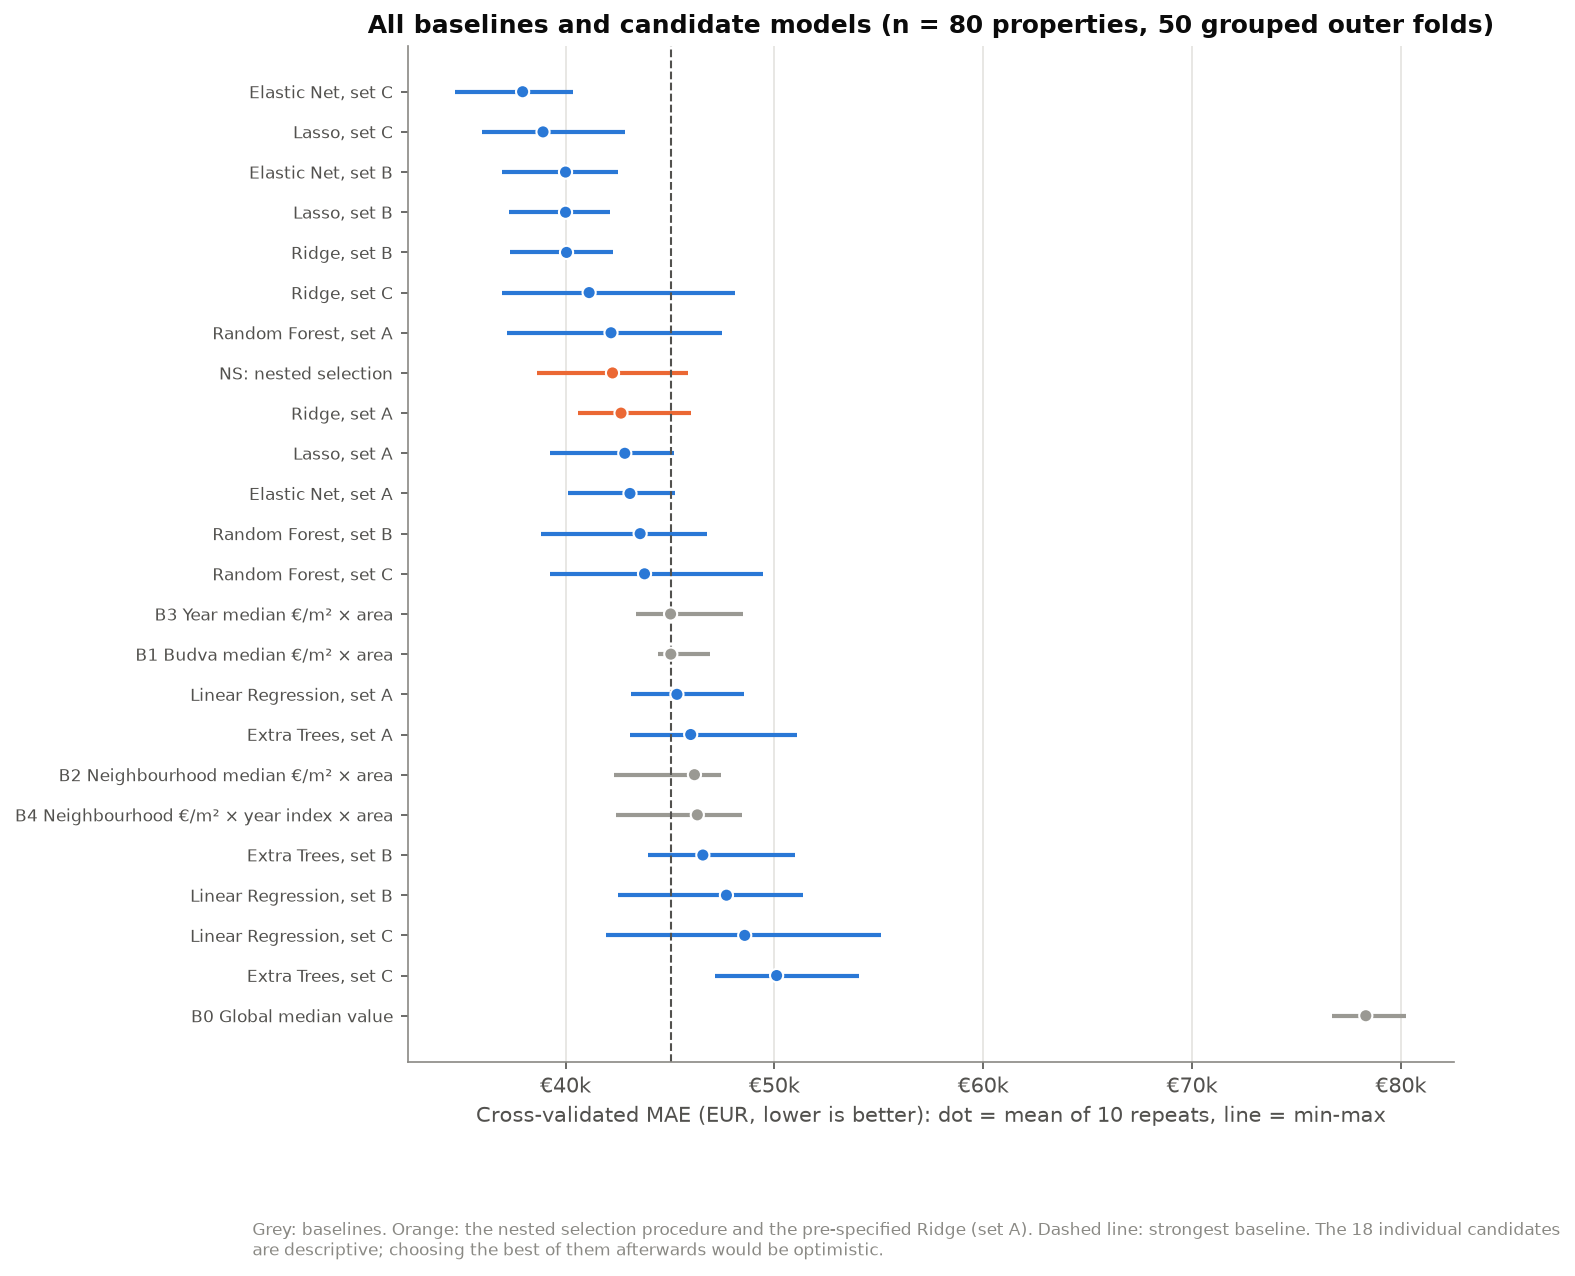

In [4]:
display(Image(bp.model_comparison(summary, highlight=[be.NS, be.H1], strongest=strongest, n=len(m))))

## 2. Does a richer feature set help? (A vs B vs C)

For each model, the three feature sets are compared on the same folds.

**What this code does:** Builds a model × feature-set table of MAE and the change from set A.

**Why we need it:** This directly tests the hypothesis that a small set of meaningful features can beat a larger one.

feature_set,A,B,C,B vs A (%),C vs A (%),best set
model,,,,,,
Linear Regression,45334.4,47705.2,48580.1,-5.2,-7.2,A
Ridge,42657.6,40049.2,41130.6,6.1,3.6,B
Lasso,42838.1,40001.6,38922.9,6.6,9.1,C
Elastic Net,43086.3,40001.1,37946.1,7.2,11.9,C
Random Forest,42178.2,43572.5,43783.3,-3.3,-3.8,A
Extra Trees,45993.6,46575.8,50107.5,-1.3,-8.9,A


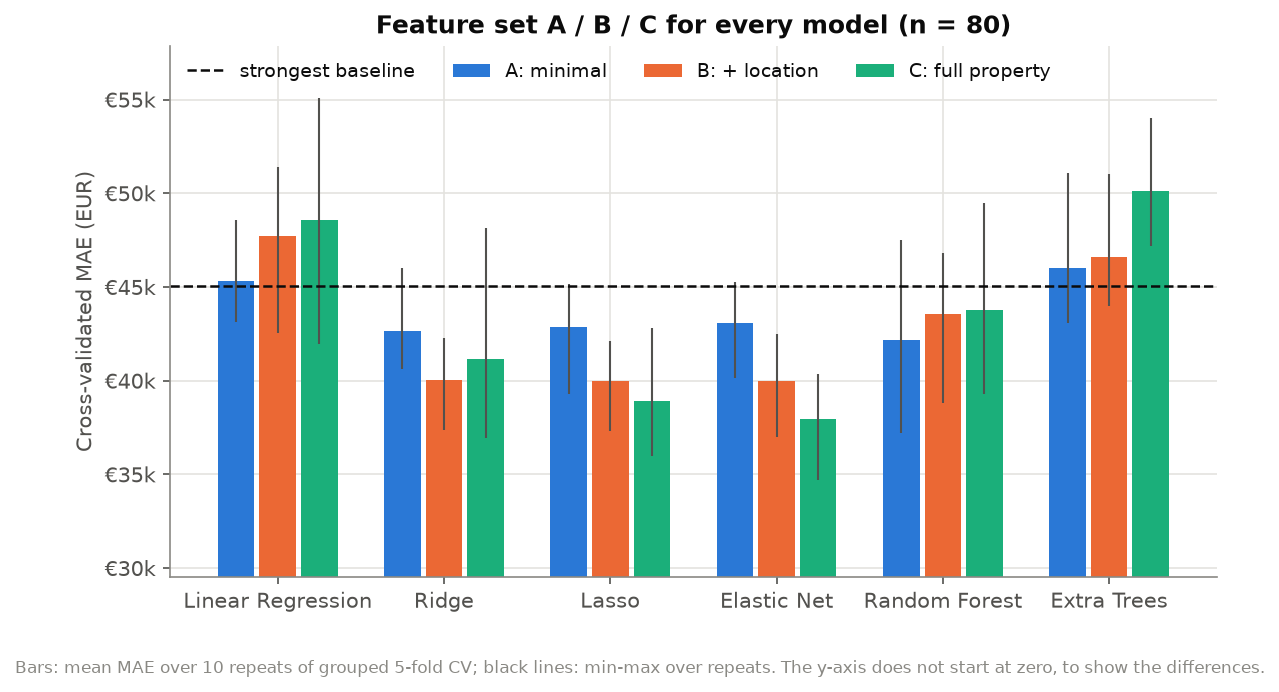

In [5]:
cand = summary[summary['kind'] == 'candidate']
abc = cand.pivot(index='model', columns='feature_set', values='MAE').loc[list(dict.fromkeys(cand['model']))]
abc['B vs A (%)'] = 100 * (abc['A'] - abc['B']) / abc['A']
abc['C vs A (%)'] = 100 * (abc['A'] - abc['C']) / abc['A']
abc['best set'] = abc[['A', 'B', 'C']].idxmin(axis=1)
abc.to_csv(bd.RESULTS_DIR / 'feature_set_comparison.csv', encoding='utf-8', lineterminator='\n')
display(abc.round(1))
display(Image(bp.feature_set_comparison(summary, summary.loc[summary['model_id'] == strongest, 'MAE'].iloc[0], len(m))))

**What this code does:** Counts, for every model, in how many of the 50 outer folds the larger set (B or C) beats set A.

**Why we need it:** An average can hide that a set wins only in a few folds; the fold count shows how consistent the difference is.

In [6]:
fw = folds[folds['kind'] == 'candidate'].assign(model=lambda d: d['model_id'].str.split(' | ', regex=False).str[0],
                                                 fs=lambda d: d['model_id'].str.split(' | ', regex=False).str[1])
piv = fw.pivot_table(index=['model', 'repeat', 'fold'], columns='fs', values='test_mae')
wins = piv.groupby('model').apply(lambda g: pd.Series({'B better than A (folds)': int((g['B'] < g['A']).sum()),
                                                       'C better than A (folds)': int((g['C'] < g['A']).sum()),
                                                       'folds': len(g)}))
wins.loc[list(dict.fromkeys(cand['model']))]

,B better than A (folds),C better than A (folds),folds
model,,,
Linear Regression,15,23,50
Ridge,36,24,50
Lasso,35,36,50
Elastic Net,34,38,50
Random Forest,20,13,50
Extra Trees,24,11,50


## 3. The nested selection procedure: which candidate does it choose?

**What this code does:** Counts how often each candidate is chosen by the inner CV across the 50 outer folds, and saves the counts.

**Why we need it:** If the choice changes a lot between folds, no single model is clearly best; if it is stable, the selected model is a robust choice.

In [7]:
sel = folds.loc[folds['model_id'] == be.NS, 'best_params'].value_counts().rename('times chosen (of 50)').to_frame()
sel.index.name = 'candidate'
sel.to_csv(bd.RESULTS_DIR / 'ns_selection_counts.csv', encoding='utf-8', lineterminator='\n')
sel

,times chosen (of 50)
candidate,
Elastic Net | C,16
Ridge | C,8
Lasso | C,8
Elastic Net | B,6
Ridge | B,4
Elastic Net | A,2
Ridge | A,2
Random Forest | A,1
Extra Trees | A,1


**What this code does:** Shows how often each hyperparameter value is chosen for the main candidates.

**Why we need it:** Hyperparameters that jump between folds show that the result depends on tuning; stable ones show the opposite.

In [8]:
for cid in ['Ridge | A', 'Ridge | C', 'Lasso | A', 'Random Forest | A', 'Random Forest | C']:
    print(f'{cid:20s}', folds.loc[folds['model_id'] == cid, 'best_params'].value_counts().to_dict())

Ridge | A            {'alpha=3': 33, 'alpha=1': 8, 'alpha=10': 7, 'alpha=0.3': 1, 'alpha=0.03': 1}
Ridge | C            {'alpha=3': 31, 'alpha=10': 13, 'alpha=1': 3, 'alpha=0.1': 1, 'alpha=0.03': 1, 'alpha=0.3': 1}
Lasso | A            {'alpha=0.03': 23, 'alpha=0.01': 22, 'alpha=0.003': 2, 'alpha=0.001': 1, 'alpha=0.0003': 1, 'alpha=0.1': 1}
Random Forest | A    {'max_features=1.0, min_samples_leaf=4': 34, 'max_features=1.0, min_samples_leaf=2': 15, 'max_features=0.5, min_samples_leaf=2': 1}
Random Forest | C    {'max_features=1.0, min_samples_leaf=2': 30, 'max_features=1.0, min_samples_leaf=4': 16, 'max_features=0.5, min_samples_leaf=4': 2, 'max_features=1.0, min_samples_leaf=8': 1, 'max_features=0.5, min_samples_leaf=2': 1}


## 4. Stability across repeats and folds

**What this code does:** Draws the MAE per repeat and the spread over the 50 folds for the strongest baseline, NS and the pre-specified Ridge (set A).

**Why we need it:** A real improvement should hold in most repeats, not just on average.

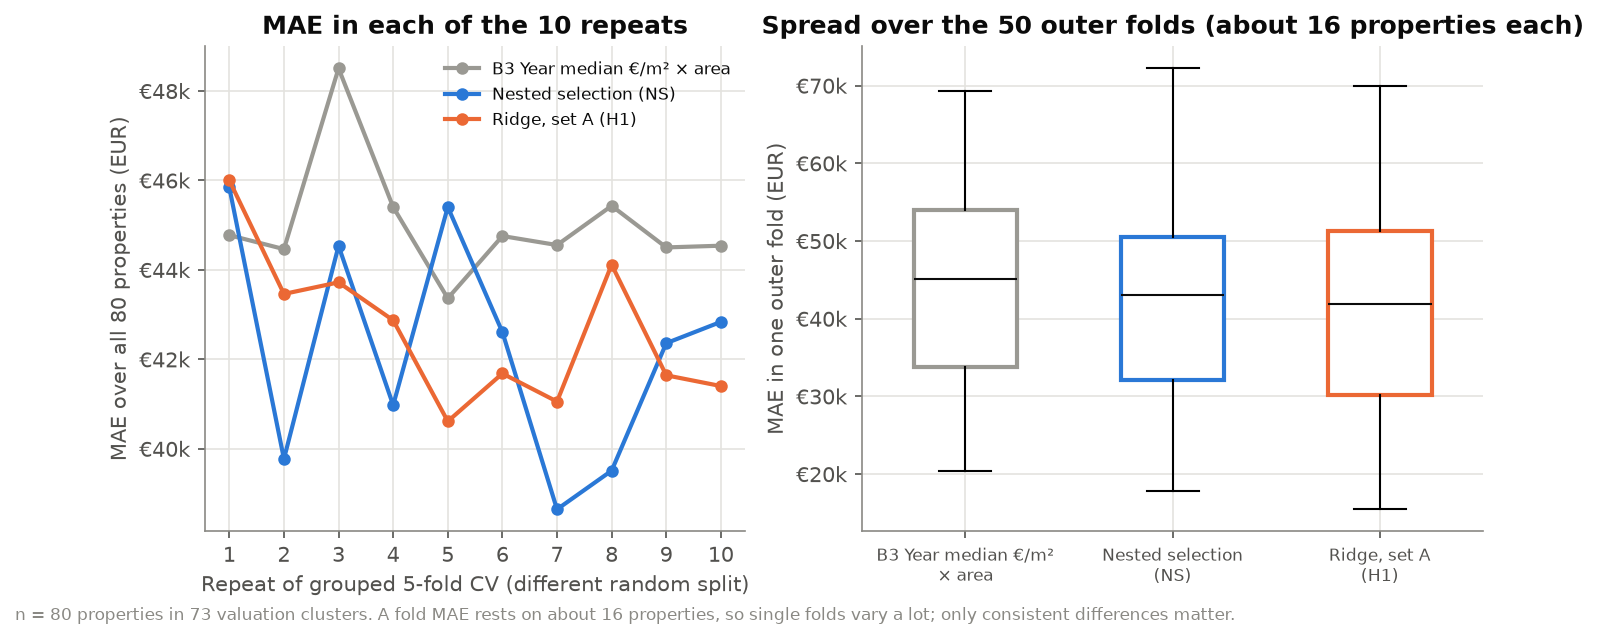

model_id       B3  NS: nested selection  Ridge | A
repeat                                            
0         44776.0               45843.0    46000.0
1         44465.0               39773.0    43462.0
2         48506.0               44537.0    43722.0
3         45405.0               40976.0    42873.0
4         43365.0               45405.0    40614.0
5         44757.0               42609.0    41684.0
6         44556.0               38647.0    41056.0
7         45432.0               39511.0    44117.0
8         44503.0               42362.0    41644.0
9         44541.0               42838.0    41403.0


In [9]:
per_rep = be.per_repeat_metrics(preds)
per_rep.to_csv(bd.RESULTS_DIR / 'cv_per_repeat.csv', index=False, encoding='utf-8', lineterminator='\n')
ids = [strongest, be.NS, be.H1]
labels = [BASELINES[strongest][0], 'Nested selection (NS)', 'Ridge, set A (H1)']
display(Image(bp.stability(per_rep, folds, ids, labels, [bp.GREY, bp.BLUE, bp.ORANGE], len(m))))
print(per_rep[per_rep['model_id'].isin(ids)].pivot(index='repeat', columns='model_id', values='MAE').round(0).to_string())

## 5. Linear coefficients: are the effects stable?

**What this code does:** Summarises the Ridge (set C) coefficients over the 50 outer folds: mean, 5-95% range and how often the sign stays the same.

**Why we need it:** A feature whose sign flips between folds carries no reliable signal in this sample, however plausible it looks.

,mean,p05,p95,same_sign
feature,,,,
log_area__area_m2,0.324,0.246,0.394,1.000
num__appraisal_year,0.151,0.114,0.182,1.000
cat__neighborhood_group_Centar,0.140,0.045,0.354,1.000
num__building_age_years,-0.129,-0.184,-0.056,1.000
cat__neighborhood_group_infrequent_sklearn,-0.120,-0.245,-0.038,1.000
cat__neighborhood_group_Bečići,-0.118,-0.232,-0.049,1.000
cat__neighborhood_group_Dubovica,0.116,0.024,0.202,1.000
cat__neighborhood_group_Obilaznica,0.116,0.040,0.252,1.000
cat__neighborhood_group_Elmosove zgrade,-0.112,-0.242,-0.042,1.000


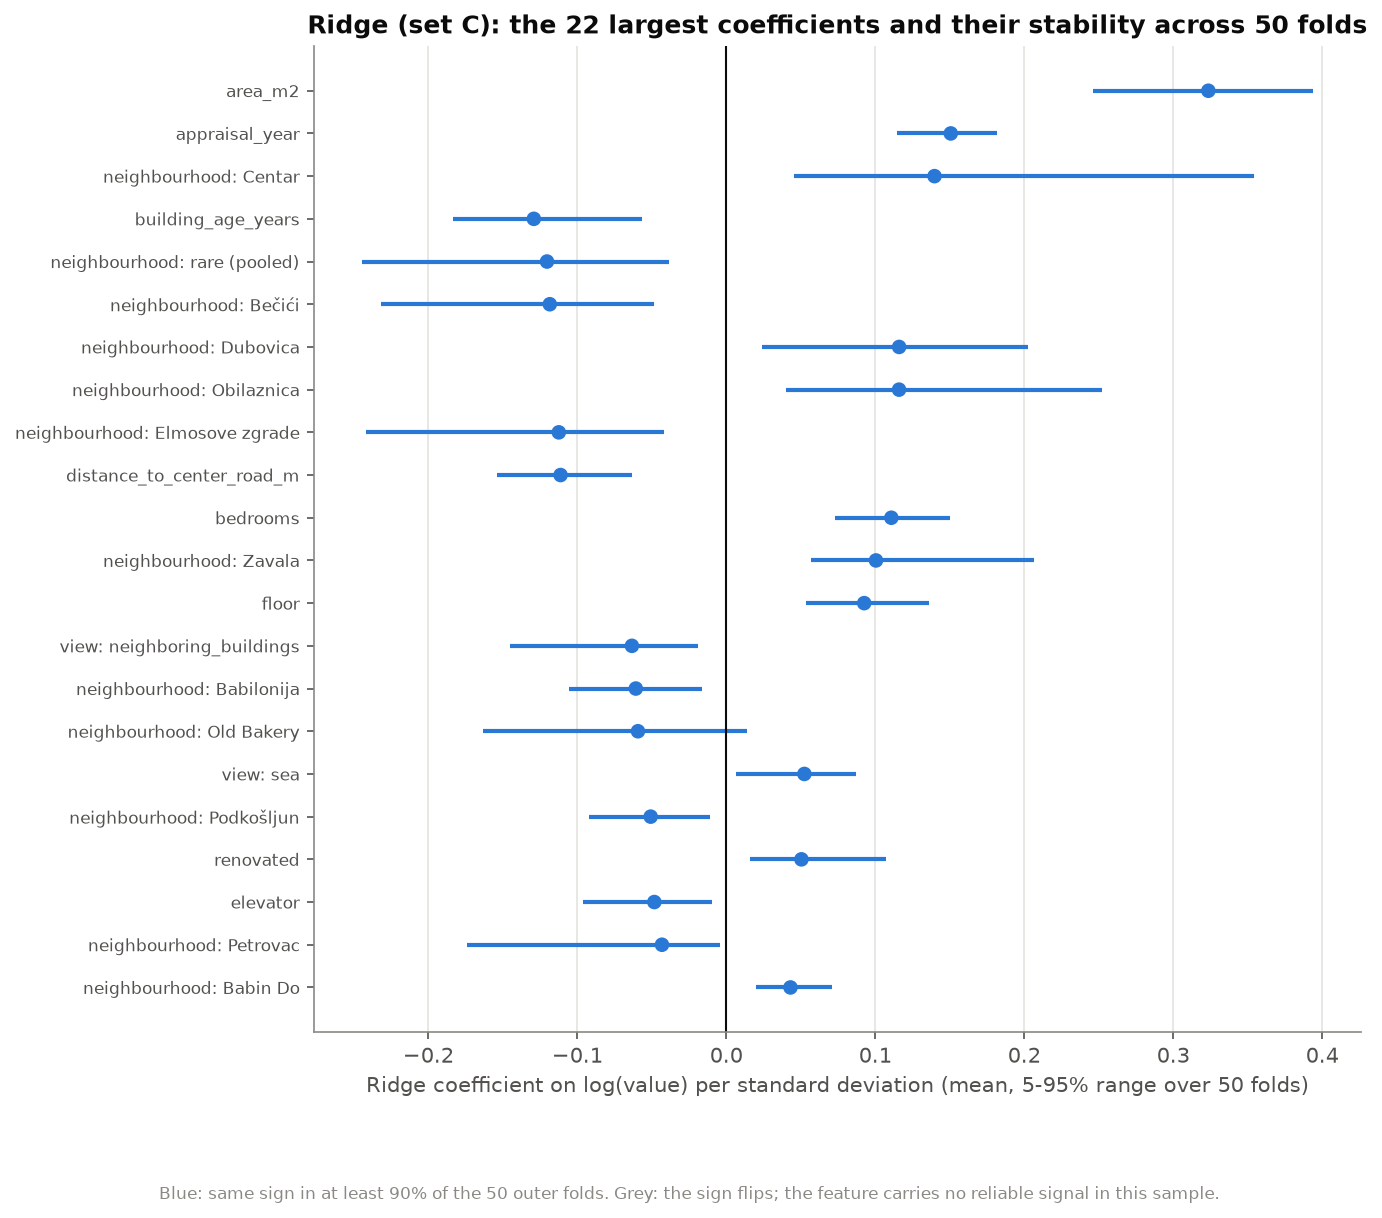

In [10]:
rc = coefs[coefs['model_id'] == 'Ridge | C']
coef_tab = rc.groupby('feature')['coef'].agg(mean='mean', p05=lambda c: c.quantile(.05), p95=lambda c: c.quantile(.95),
                                              same_sign=lambda c: max((c > 0).mean(), (c < 0).mean()))
coef_tab = coef_tab.reindex(coef_tab['mean'].abs().sort_values(ascending=False).index)
coef_tab.to_csv(bd.RESULTS_DIR / 'ridge_C_coefficients.csv', encoding='utf-8', lineterminator='\n')
display(coef_tab.round(3).head(20))
display(Image(bp.coefficient_stability(rc)))

## 6. Training versus validation error

**What this code does:** Compares the training MAE and the outer-fold MAE of every candidate.

**Why we need it:** A large gap means the model memorises the training properties instead of learning a general pattern.

In [11]:
gap = summary[summary['kind'] != 'baseline'][['model_id', 'train_MAE', 'MAE']].copy()
gap['validation / training'] = gap['MAE'] / gap['train_MAE']
gap.sort_values('validation / training', ascending=False).round(2)

,model_id,train_MAE,MAE,validation / training
7,Linear Regression | C,15723.20,48580.13,3.09
21,Extra Trees | B,20956.86,46575.83,2.22
22,Extra Trees | C,24778.40,50107.51,2.02
20,Extra Trees | A,23380.83,45993.59,1.97
6,Linear Regression | B,24453.26,47705.22,1.95
19,Random Forest | C,23441.64,43783.30,1.87
5,Linear Regression | A,24909.63,45334.38,1.82
10,Ridge | C,22767.41,41130.63,1.81
18,Random Forest | B,24458.02,43572.53,1.78
23,NS: nested selection,28266.30,42250.07,1.49
